# PathSnap: HMM + Viterbi route reconstruction

Runs the shipped inference pipeline on all 10 `student_test` trips and compares classifier-only predictions with classifier + HMM:

- **Classifier:** the tuned XGBoost in `artifacts/model.joblib` (see `artifacts/metadata.json`).
- **Decoder:** `artifacts/hmm.json` (emissions = log classifier probability, transitions = Newson & Krumm route-vs-GPS distance, Viterbi in log space). See `src/hmm.py`.
- **No ground truth at inference:** `predict_trip` runs with `trip.route = None`; the reference route is used only afterwards by `score_trip`.

Outputs:

| Path | Content |
|---|---|
| `results/hmm/xgboost/classifier_vs_hmm.csv` | one row per trip: Top-1, route continuity, route precision/recall/F1, timings |
| `results/hmm/xgboost/integration_summary.json` | means, trips improved, timings and decoder settings of the run |
| `results/hmm/xgboost/predictions.parquet` | per-fix `trip_id, fix_idx, arc_clf, arc_hmm` (input for `python -m src.result_maps --predictions`) |
| `results/hmm/xgboost/hmm_non_improvements.csv`, `classifier_vs_hmm.png` | trips where the HMM did not raise Top-1; summary plot |
| `maps/results/xgboost_hmm/` | maps of the two trips where the HMM helped least |

**Local:** `jupyter notebook notebooks/julia_hmm_viterbi_colab.ipynb` from the project root, after `pip install -r requirements.txt`.
**Colab:** Runtime → Run all. The notebook clones the repository (the dataset is in it) and installs the pinned requirements.
The same evaluation without a notebook: `python scripts/run_julia_hmm.py --skip-tune`.

In [1]:
# Settings
BRANCH = "main"          # Colab only: branch to clone
RETUNE_HMM = False       # True: re-tune beta / gap / emission weight on TRAIN trips and overwrite artifacts/hmm.json
TUNE_TRIPS = 3           # TRAIN trips used when RETUNE_HMM is True (80 = all; slow)

import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules


def sh(*cmd, cwd=None):
    """Run a command, show its output in the notebook, stop on failure."""
    shown = ["python" if c == sys.executable else str(c) for c in cmd]
    print("$", " ".join(shown), flush=True)
    proc = subprocess.Popen([str(c) for c in cmd], cwd=cwd, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    for line in proc.stdout:
        print(line, end="", flush=True)
    if proc.wait() != 0:
        raise RuntimeError(f"command failed with exit code {proc.returncode}")


def find_project():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "src" / "pipeline.py").exists() and (p / "artifacts").is_dir():
            return p
    return None


PROJECT = find_project()
if PROJECT is None:
    if not IN_COLAB:
        raise RuntimeError("Run this notebook from inside the pathsnap repository (e.g. notebooks/).")
    PROJECT = Path("/content/pathsnap")
    if not PROJECT.exists():
        sh("git", "clone", "--depth", "1", "--branch", BRANCH,
           "https://github.com/Krishna17092006/pathsnap.git", PROJECT)
    sh(sys.executable, "-m", "pip", "install", "-q", "-r", PROJECT / "requirements.txt")

os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
print("Project root:", PROJECT.name)

Project root: pathsnap


## 1. Which classifier and decoder will be used

Checks that `artifacts/model.joblib` is a real model (not a Git LFS pointer) and prints the classifier behind the HMM emissions.

In [2]:
import json
from src.pipeline import load_artifacts

model_file = PROJECT / "artifacts" / "model.joblib"
if model_file.exists():
    assert not model_file.read_bytes()[:40].startswith(b"version https://git-lfs"), \
        "artifacts/model.joblib is a Git LFS pointer: run `git lfs pull` first"
    meta = json.loads((PROJECT / "artifacts" / "metadata.json").read_text())
    print(f"artifacts/metadata.json: {meta['model']} ({meta.get('source')}) - {meta.get('description')}")

art = load_artifacts(PROJECT / "artifacts")
bundle = art["model_bundle"]
estimator = bundle.steps[-1][1] if hasattr(bundle, "steps") else bundle
MODEL = art["model_name"]
print("pipeline loads:   ", Path(art["model_path"]).name if art["model_path"] else None)
print("estimator:        ", type(estimator).__name__)
print("emission model:   ", MODEL, f"-> results/hmm/{MODEL}/")
assert MODEL == "xgboost", f"artifacts/ holds {MODEL!r}; this notebook evaluates the tuned XGBoost"
print("decoder (hmm.json):", art["decoder_config"].to_dict())

artifacts/metadata.json: xgboost (tuned) - XGBoost hist, 350 trees, lr=0.06, max_depth=6, subsample/colsample 0.85, reg_lambda=2 (Optuna-tuned)


pipeline loads:    model.joblib
estimator:         XGBClassifier
emission model:    xgboost -> results/hmm/xgboost/
decoder (hmm.json): {'beta': 100.0, 'sigma': 8.0, 'gap_threshold_s': 30.0, 'emission_weight': 1.0, 'max_speed_mps': 50.0, 'min_transition_m': 200.0, 'probability_epsilon': 1e-06}


## 2. (Optional) Re-tune the decoder on TRAIN trips

Off by default: `artifacts/hmm.json` keeps the committed decoder settings. Tuning never reads `student_test` or evaluator trips.

In [3]:
if RETUNE_HMM:
    sh(sys.executable, "-m", "src.tune_hmm", "--max-trips", TUNE_TRIPS)
    art = load_artifacts(PROJECT / "artifacts")
    print("decoder after tuning:", art["decoder_config"].to_dict())
else:
    print("Skipped: using artifacts/hmm.json")

Skipped: using artifacts/hmm.json


## 3. Classifier-only vs classifier + HMM on all 10 student-test trips

In [4]:
sh(sys.executable, "-m", "src.evaluate_hmm")

$ python -m src.evaluate_hmm


Emission model: xgboost (artifacts/model.joblib); decoder: {'beta': 100.0, 'sigma': 8.0, 'gap_threshold_s': 30.0, 'emission_weight': 1.0, 'max_speed_mps': 50.0, 'min_transition_m': 200.0, 'probability_epsilon': 1e-06}


00000000: classifier Top-1=0.9433, HMM Top-1=0.9417, time=3978 ms


00000007: classifier Top-1=0.9321, HMM Top-1=0.8870, time=1974 ms


00000009: classifier Top-1=0.8723, HMM Top-1=0.8723, time=1773 ms


00000040: classifier Top-1=0.9376, HMM Top-1=0.9139, time=4514 ms


... (4 outputs left out)

00000077: classifier Top-1=0.7216, HMM Top-1=0.6584, time=6261 ms


00000091: classifier Top-1=0.8707, HMM Top-1=0.8398, time=1553 ms


Saved comparison to results/hmm/xgboost/


Result maps: maps/results/xgboost_hmm/


## 4. Results

,trip_id,n_fixes,top1_classifier,top1_hmm,route_continuity_clf,route_continuity_hmm,classifier_route_f1,hmm_route_f1,inference_ms
0,00000000,2503,0.9433,0.9417,0.9736,0.9892,0.7506,0.7731,3977.9056
1,00000007,1354,0.9321,0.8870,0.9978,0.9985,0.7139,0.7781,1974.3166
2,00000009,1049,0.8723,0.8723,0.8979,0.9313,0.8227,0.8284,1772.5539
3,00000040,2995,0.9376,0.9139,0.9813,0.9856,0.7332,0.7088,4513.7775
4,00000052,262,0.9542,0.9885,0.9464,0.9655,0.8571,0.9326,538.5848
5,00000056,3958,0.9003,0.9089,0.9224,0.9606,0.8291,0.8784,6916.9514
6,00000065,768,0.8385,0.7812,0.9530,0.9634,0.7159,0.7401,1309.9346
7,00000076,1486,0.8742,0.8728,0.9151,0.9468,0.7485,0.7734,4833.4254
8,00000077,3911,0.7216,0.6584,0.9504,0.9657,0.3053,0.3030,6261.1172
9,00000091,874,0.8707,0.8398,0.9049,0.9267,0.7063,0.7179,1553.4562


Emission model: xgboost   decoder: beta=100.0, gap=30.0 s, emission weight=1.0
Trips: 10, integration failures: 0
                        classifier     + HMM   trips improved
Top-1                       0.8845    0.8665           2 / 10
Route continuity            0.9443    0.9633          10 / 10
Route F1                    0.7183    0.7434           8 / 10
Inference: mean 3.37 s, max 6.92 s per trip


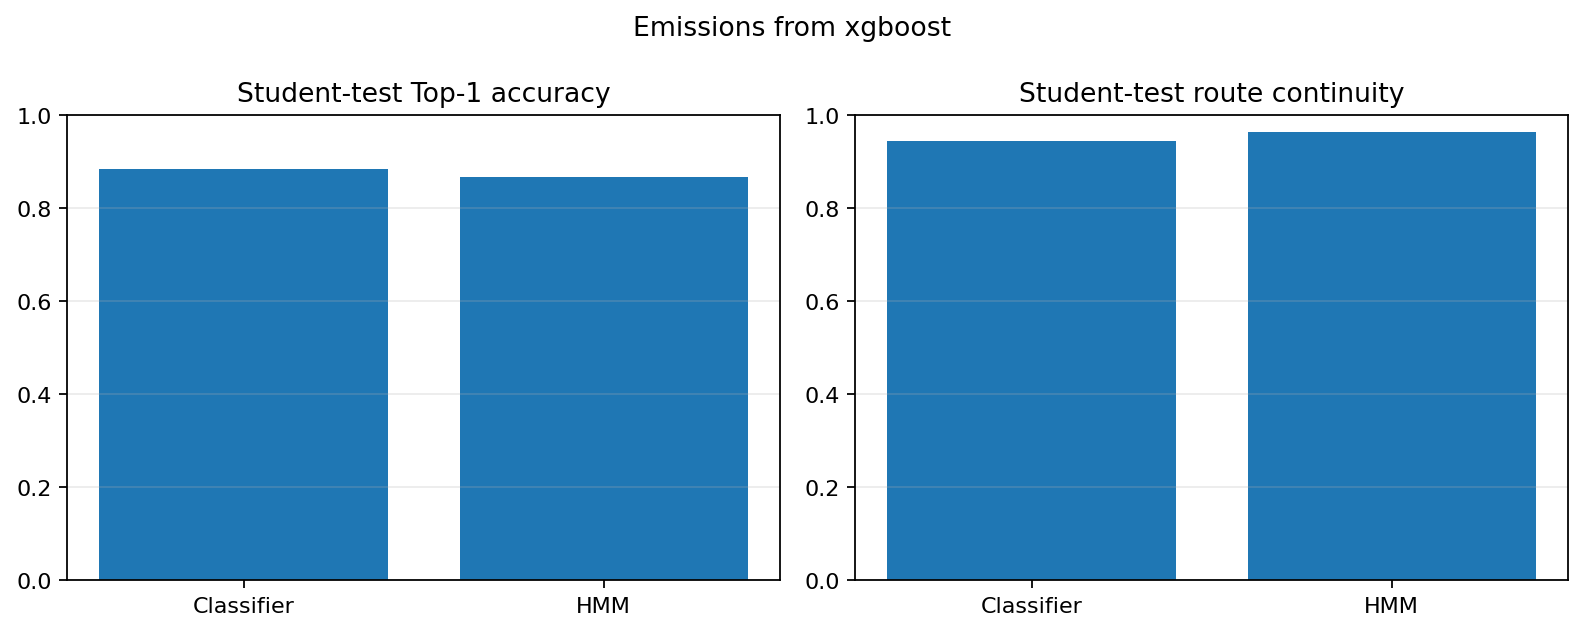

In [5]:
import pandas as pd
from IPython.display import Image, display

out = PROJECT / "results" / "hmm" / MODEL
r = pd.read_csv(out / "classifier_vs_hmm.csv", dtype={"trip_id": str})
s = json.loads((out / "integration_summary.json").read_text())

cols = ["trip_id", "n_fixes", "top1_classifier", "top1_hmm", "route_continuity_clf", "route_continuity_hmm",
        "classifier_route_f1", "hmm_route_f1", "inference_ms"]
display(r[cols].round(4))

m = s["student_test_means"]
print(f"Emission model: {s['emission_model']}   decoder: beta={s['decoder']['beta']}, "
      f"gap={s['decoder']['gap_threshold_s']} s, emission weight={s['decoder']['emission_weight']}")
print(f"Trips: {s['n_student_test_trips']}, integration failures: {s['n_integration_failures']}")
print(f"{'':22s}{'classifier':>12s}{'+ HMM':>10s}{'trips improved':>17s}")
for label, a, b, k in [("Top-1", "top1_classifier", "top1_hmm", "top1"),
                       ("Route continuity", "route_continuity_clf", "route_continuity_hmm", "route_continuity"),
                       ("Route F1", "classifier_route_f1", "hmm_route_f1", "route_f1")]:
    print(f"{label:22s}{m[a]:12.4f}{m[b]:10.4f}{s['trips_improved_by_hmm'][k]:>12d} / {len(r)}")
print(f"Inference: mean {s['mean_inference_ms'] / 1000:.2f} s, max {s['max_inference_ms'] / 1000:.2f} s per trip")
display(Image(filename=str(out / "classifier_vs_hmm.png")))

assert s["n_integration_failures"] == 0, "some trips failed: see integration_failures.csv"
assert len(r) == 10, "expected all 10 student_test trips"

## 5. Unit tests (HMM decoder and classifier compatibility)

In [6]:
sh(sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "tests/test_hmm.py", "tests/test_pipeline_models.py")

$ python -m pytest -q -p no:cacheprovider tests/test_hmm.py tests/test_pipeline_models.py


................                                                         [100%]


16 passed in 3.43s


## 6. Download the outputs (Colab only)

In [7]:
if IN_COLAB:
    import shutil
    from google.colab import files
    zip_path = shutil.make_archive(f"/content/hmm_{MODEL}_results", "zip", PROJECT, f"results/hmm/{MODEL}")
    files.download(zip_path)
else:
    print("Outputs are in", out.relative_to(PROJECT), "and", f"maps/results/{MODEL}_hmm/")

Outputs are in results\hmm\xgboost and maps/results/xgboost_hmm/
